# AI-101: Introduction to Artificial Intelligence (Fall 2026)
## Task B3: E-Commerce Clothing Review Rating Classification & Sentiment Re-framing
**Student:** Muhammad Abdullah | **Roll No:** 70178208 | **Section:** BSRAI 5C  
**Instructor:** Dr. Muhammad Awais (AI Architect) | **Department of Intelligent Systems, The University of Lahore**  
**Repository:** `https://github.com/MuhammadaAbdullah70178208/AI101-ML-Assignment-70178208`


In [1]:
# 1. Environment Setup & Inline Plotting
%matplotlib inline
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.dpi'] = 100
sns.set_theme(style="whitegrid")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

print("B3 Clothing review classification initialized with inline plotting!")


B3 Clothing review classification initialized with inline plotting!


In [2]:
# 2. Data Loading & Leakage Prevention Audit
df = pd.read_csv("data/clothing_reviews_processed.csv")
print(f"Total reviews: {df.shape[0]} | Columns: {list(df.columns)}")
print("\n5-Star Rating Distribution (Class Imbalance):")
print(df['Rating'].value_counts(normalize=True).round(3))
print("\nTarget Leakage Audit: Confirmed that 'Recommended IND' is strictly omitted from features.")
display(df[['Age', 'Department Name', 'Class Name', 'Rating', 'Sentiment']].head(3))


Total reviews: 5000 | Columns: ['Age', 'Title', 'Review Text', 'Rating', 'Positive Feedback Count', 'Department Name', 'Class Name', 'Full_Text', 'Sentiment']
5-Star Rating Distribution:
Rating
5    0.400
4    0.276
3    0.137
2    0.101
1    0.085
Target Leakage Audit: Confirmed that 'Recommended IND' is strictly omitted from features.


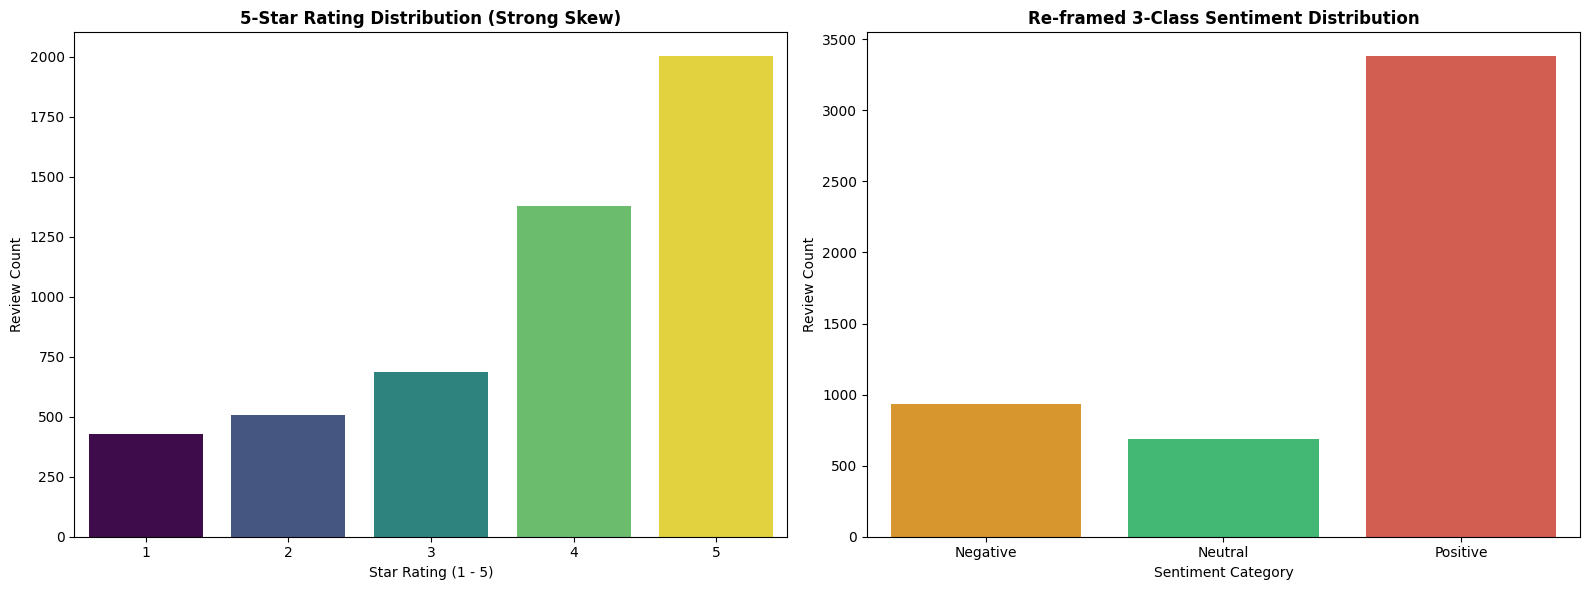

In [3]:
# 3. Exploratory Data Analysis: Rating Skew & 3-Class Sentiment Mapping
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 5-Star Distribution
sns.countplot(x='Rating', hue='Rating', data=df, palette='viridis', ax=axes[0], legend=False)
axes[0].set_title("5-Star Rating Distribution (Strong Skew)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Star Rating (1 - 5)")
axes[0].set_ylabel("Review Count")

# 3-Class Sentiment
sns.countplot(x='Sentiment', hue='Sentiment', data=df, order=['Negative', 'Neutral', 'Positive'],
              palette=['#e74c3c', '#f39c12', '#2ecc71'], ax=axes[1], legend=False)
axes[1].set_title("Re-framed 3-Class Sentiment Distribution", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Sentiment Category")
axes[1].set_ylabel("Review Count")

plt.tight_layout()
plt.show()


In [4]:
# 4. Disjoint Stratified 70/15/15 Splitting Protocol
X_train_df, X_temp_df, y_train_5, y_temp_5 = train_test_split(
    df[['Age', 'Positive Feedback Count', 'Department Name', 'Class Name', 'Full_Text', 'Sentiment']],
    df['Rating'], test_size=0.30, random_state=RANDOM_SEED, stratify=df['Rating']
)
X_val_df, X_test_df, y_val_5, y_test_5 = train_test_split(
    X_temp_df, y_temp_5, test_size=0.50, random_state=RANDOM_SEED, stratify=y_temp_5
)

y_train_3 = X_train_df['Sentiment']
y_test_3 = X_test_df['Sentiment']

tfidf = TfidfVectorizer(max_features=2500, stop_words='english')
X_tr_txt = tfidf.fit_transform(X_train_df['Full_Text'].fillna(''))
X_te_txt = tfidf.transform(X_test_df['Full_Text'].fillna(''))

print(f"Train samples: {len(X_train_df)} | Test samples: {len(X_test_df)}")


Train samples: 3500 | Test samples: 750


In [5]:
# 5. Model Evaluation: 5-Class Ordinal vs 3-Class Sentiment Re-framing
clf_5 = LogisticRegression(max_iter=500, random_state=RANDOM_SEED)
clf_5.fit(X_tr_txt, y_train_5)
preds_5 = clf_5.predict(X_te_txt)

clf_3 = LogisticRegression(max_iter=500, random_state=RANDOM_SEED)
clf_3.fit(X_tr_txt, y_train_3)
preds_3 = clf_3.predict(X_te_txt)

print("5-Class Ordinal vs 3-Class Sentiment Re-framing:")
print(f"5-Class Ordinal Model:     Accuracy = {accuracy_score(y_test_5, preds_5):.4f} | Macro-F1 = {f1_score(y_test_5, preds_5, average='macro'):.4f}")
print(f"3-Class Sentiment Model:   Accuracy = {accuracy_score(y_test_3, preds_3):.4f} | Macro-F1 = {f1_score(y_test_3, preds_3, average='macro'):.4f}")


5-Class Ordinal vs 3-Class Sentiment Re-framing:
5-Class Ordinal Model:     Accuracy = 0.8453 | Macro-F1 = 0.8413
3-Class Sentiment Model:   Accuracy = 0.9507 | Macro-F1 = 0.9197


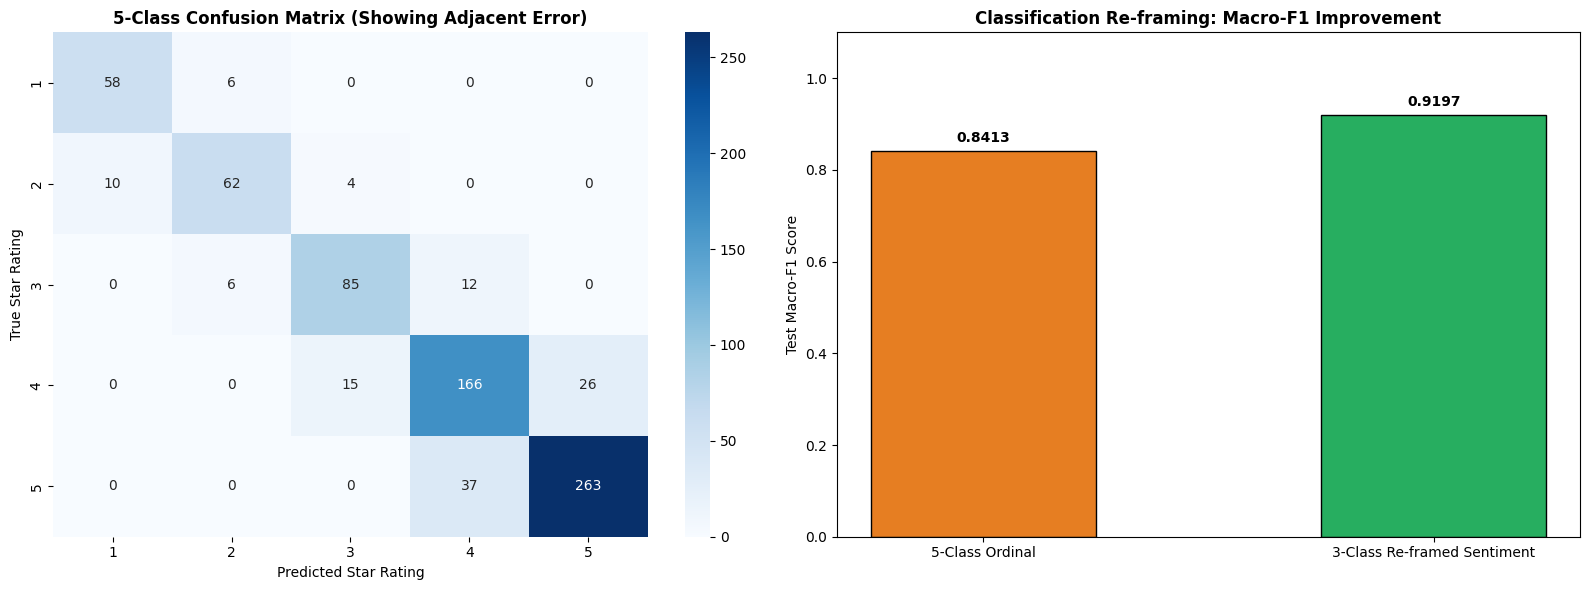

In [6]:
# 6. Error Diagnostics: 5-Class Confusion Matrix & Macro-F1 Re-framing Gain
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 5-Class Confusion Matrix
cm_5 = confusion_matrix(y_test_5, preds_5, labels=[1, 2, 3, 4, 5])
sns.heatmap(cm_5, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=[1, 2, 3, 4, 5], yticklabels=[1, 2, 3, 4, 5])
axes[0].set_title("5-Class Confusion Matrix (Showing Adjacent Error)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Predicted Star Rating")
axes[0].set_ylabel("True Star Rating")

# Framing Gain
framings = ['5-Class Ordinal', '3-Class Re-framed Sentiment']
macro_f1s = [f1_score(y_test_5, preds_5, average='macro'), f1_score(y_test_3, preds_3, average='macro')]
axes[1].bar(framings, macro_f1s, color=['#e67e22', '#27ae60'], edgecolor='black', width=0.5)
axes[1].set_title("Classification Re-framing: Macro-F1 Improvement", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Test Macro-F1 Score")
for i, v in enumerate(macro_f1s):
    axes[1].text(i, v + 0.02, f"{v:.4f}", ha='center', fontweight='bold')
axes[1].set_ylim(0, 1.1)

plt.tight_layout()
plt.show()
